In [1]:
# conda env at3d_pure

import xarray as xr
import numpy as np
import at3d
from collections import OrderedDict
import matplotlib.pyplot as plt

In [2]:
## INPUT
# RT Grid
rte_grid_file = '../intermediate_data/RTG_default.nc'
# Dropsonde
dropsondeFile = '../../data/CAMP2Ex_Dropsonde/CAMP2EX-dropsondes_P3B_20191002022856_R0.nc'
# Wavelength
wavelength = 0.67

## OUTPUT
out_file = '../intermediate_data/ATMOS_S07_RTG_default.nc'

In [3]:
rte_grid = xr.load_dataset(rte_grid_file)
dropsonde = xr.load_dataset(dropsondeFile)

In [4]:
cond_pres = np.logical_not(np.isnan(dropsonde.pres.data))
cond_tdry = np.logical_not(np.isnan(dropsonde.tdry.data))
cond_gpsalt = np.logical_not(np.isnan(dropsonde.gpsalt.data))
cond = cond_pres & cond_tdry & cond_gpsalt

z = dropsonde.gpsalt.data[cond] / 1000
z[0] = 0 # Force bottom to be at zero

atmosphere = xr.Dataset(
    data_vars={
        'temperature': (['z'], dropsonde.tdry.data[cond] + 273.15),
        'pressure': (['z'], dropsonde.pres.data[cond])
    },
    coords={
        'z': z
    }
)

atmosphere_optical_properties = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid)


In [5]:
"""
Account for the molecular atmosphere above the domain by changing the extinction in the top layer.
This algorithm ensures that the 'compensated' optical depth agrees with the 'exact' optical depth.
"""
rte_grid_exact = rte_grid.copy(deep=True)
rte_grid_exact['z'] = atmosphere.z
atmosphere_optical_properties_exact = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid_exact)
tau_exact = atmosphere_optical_properties_exact[wavelength].isel(x=0,y=0).extinction.integrate('z').data

rte_grid_minus1 = rte_grid.copy(deep=True)
rte_grid_minus1['z'] = rte_grid.z[:-1]
atmosphere_optical_properties_minus1 = at3d.rayleigh.to_grid(wavelength, atmosphere, rte_grid_minus1)
tau_minus1 = atmosphere_optical_properties_minus1[wavelength].isel(x=0,y=0).extinction.integrate('z').data

del_tau = tau_exact - tau_minus1
h = rte_grid.z.data[-1] - rte_grid.z.data[-2]
xmax = atmosphere_optical_properties_minus1[wavelength].isel(x=0,y=0, z=-1).extinction.data
compensation_extinction = ((2*del_tau)/h) - xmax
atmosphere_optical_properties_comp = {}
atmosphere_optical_properties_comp[wavelength] = atmosphere_optical_properties[wavelength].copy(deep=True)
extinction = atmosphere_optical_properties[wavelength].extinction.copy(deep=True).data
extinction[:,:,-1] = compensation_extinction
atmosphere_optical_properties_comp[wavelength]['extinction'] = (['x','y','z'], extinction)

In [6]:
atmosphere_optical_properties_comp[wavelength].to_netcdf(out_file)

tau_exact:  0.01784
tau_comp:   0.01784
tau:        0.00814
tau minus1: 0.00730


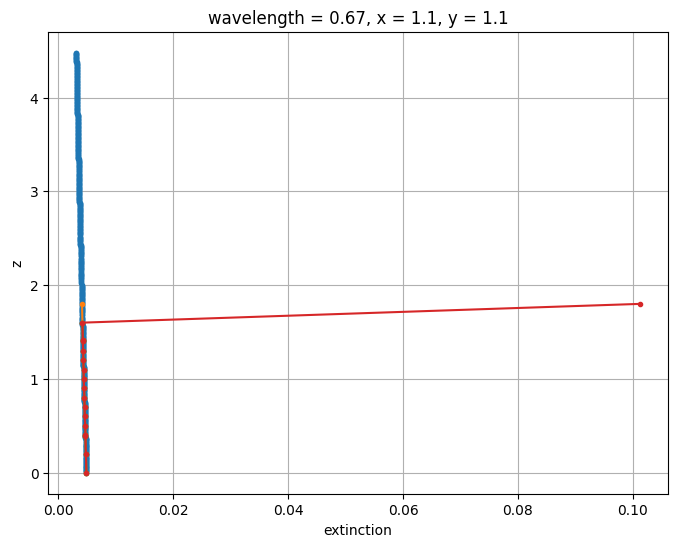

In [7]:
# PLOT CORRECTED EXTINCTION
f, ax = plt.subplots(1, 1, figsize=(8,6))
atmosphere_optical_properties_exact[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties_minus1[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
atmosphere_optical_properties_comp[wavelength].isel(x=4,y=4).extinction.plot(y='z', marker='.', ax=ax)
ax.grid()
tau_exact = atmosphere_optical_properties_exact[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau_comp = atmosphere_optical_properties_comp[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau = atmosphere_optical_properties[wavelength].isel(x=4,y=4).extinction.integrate('z').data
tau_minus1 = atmosphere_optical_properties_minus1[wavelength].isel(x=4,y=4).extinction.integrate('z').data
print('tau_exact:  {:.5f}'.format(tau_exact))
print('tau_comp:   {:.5f}'.format(tau_comp))
print('tau:        {:.5f}'.format(tau))
print('tau minus1: {:.5f}'.format(tau_minus1))